# RBLA Pipeline：不同广播方法的加权误差

读取本 pipeline 文件夹中的 CSV，并绘制各方法每轮的 `weighted_error`。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PIPELINE_NAME = 'rbla_pipeline'
DATA_DIR = Path.cwd()
if not list(DATA_DIR.glob('*.csv')):
    DATA_DIR = Path('close-optimal-result/aggregation_broadcast_error/imdb') / PIPELINE_NAME

csv_files = sorted(DATA_DIR.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f'在 {DATA_DIR.resolve()} 中没有找到 CSV 文件')

frames = []
required_columns = {'round', 'evaluated_method', 'weighted_error'}
for csv_file in csv_files:
    frame = pd.read_csv(csv_file)
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f'{csv_file.name} 缺少列: {sorted(missing)}')
    frame = frame.copy()
    frame['source_file'] = csv_file.name
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)
data['round'] = pd.to_numeric(data['round'], errors='coerce')
data['weighted_error'] = pd.to_numeric(data['weighted_error'], errors='coerce')
data = data.dropna(subset=['round', 'weighted_error']).sort_values(['evaluated_method', 'round'])
print(f'Pipeline: {PIPELINE_NAME}')
print(f'读取文件数: {len(csv_files)}')
data[['evaluated_method', 'round', 'weighted_error', 'source_file']].head()

Pipeline: rbla_pipeline
读取文件数: 4


,evaluated_method,round,weighted_error,source_file
0,fedss_0_4,0,12.117329,rbla_-aggregation_broadcast_train-20260818_231...
1,fedss_0_4,1,11.098967,rbla_-aggregation_broadcast_train-20260818_231...
2,fedss_0_4,2,9.391318,rbla_-aggregation_broadcast_train-20260818_231...
3,fedss_0_4,3,9.531403,rbla_-aggregation_broadcast_train-20260818_231...
4,fedss_0_4,4,10.442792,rbla_-aggregation_broadcast_train-20260818_231...


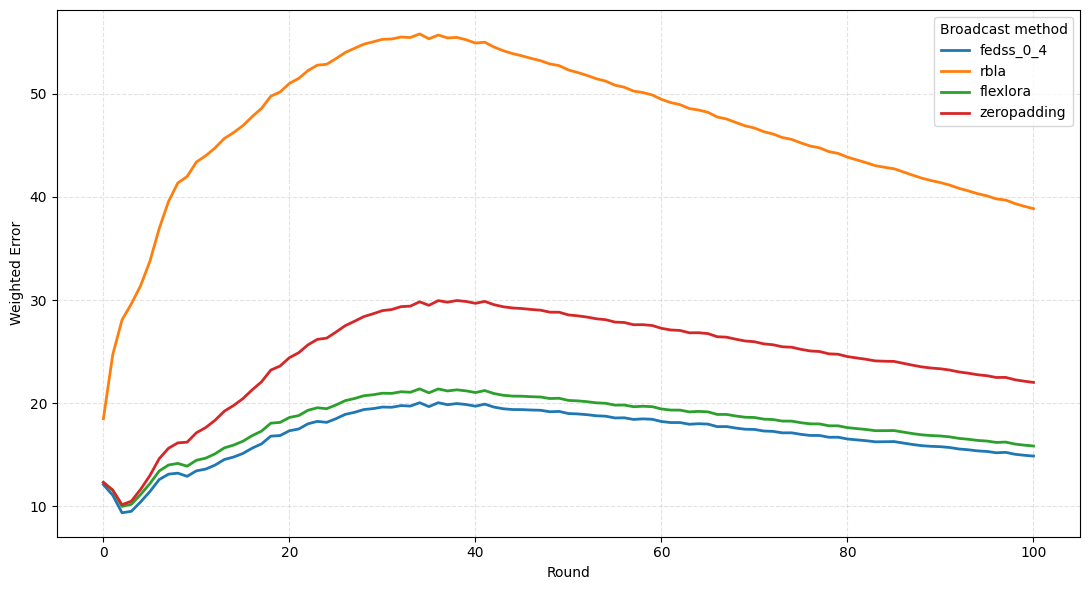

In [2]:
fig, ax = plt.subplots(figsize=(11, 6))
for method, method_data in data.groupby('evaluated_method', sort=True):
    ax.plot(method_data['round'], method_data['weighted_error'], label='flexlora' if method == 'sp' else method, linewidth=2)

ax.set_xlabel('Round')
ax.set_ylabel('Weighted Error')
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend(title='Broadcast method')
fig.tight_layout()
plt.show()